# Outlier Detection and Robust Handling

An **outlier** is an observation far from the others. It can be an error (a typo, a broken sensor), a special case (an unfinished house sold cheaply), or the most important data point (fraud). Detection finds candidates; the decision to remove, cap or keep them needs domain knowledge and measurement.

**After this lesson you can:**

1. Detect univariate outliers with z-scores, the IQR rule and robust z-scores (MAD).
2. Detect multivariate outliers with Isolation Forest.
3. Measure how outliers change a model, and choose between removing, capping (winsorising) and robust models.

**Data:** Ames Housing.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: downloads pinned public datasets

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})
RNG = 42

from sklearn.ensemble import IsolationForest
from sklearn.linear_model import HuberRegressor, LinearRegression
from sklearn.model_selection import KFold, cross_val_predict

ames = datasets.ames()
x, y = ames["Gr_Liv_Area"], ames["Sale_Price"]
print(ames[["Gr_Liv_Area", "Sale_Price"]].describe().round(0))

       Gr_Liv_Area  Sale_Price
count       2930.0      2930.0
mean        1500.0    180796.0
std          506.0     79887.0
min          334.0     12789.0
25%         1126.0    129500.0
50%         1442.0    160000.0
75%         1743.0    213500.0
max         5642.0    755000.0


## 1. Univariate Rules

| Rule | Flag if | Weakness |
| :--- | :--- | :--- |
| z-score | $\lvert x - \bar{x} \rvert / s > 3$ | mean and std are themselves pulled by outliers |
| IQR (Tukey) | $x < Q_1 - 1.5\,IQR$ or $x > Q_3 + 1.5\,IQR$ | flags many points in skewed data |
| robust z (MAD) | $0.6745\,\lvert x - \text{median} \rvert / \text{MAD} > 3.5$ | robust; needs MAD > 0 |

In [2]:
def flags(s: pd.Series) -> pd.DataFrame:
    z = (s - s.mean()) / s.std()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    mad = (s - s.median()).abs().median()
    rz = 0.6745 * (s - s.median()) / mad
    return pd.DataFrame({"z>3": z.abs() > 3, "IQR": (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr), "robust z>3.5": rz.abs() > 3.5})

f_area, f_price = flags(x), flags(y)
print("flagged houses, living area:", f_area.sum().to_dict())
print("flagged houses, sale price :", f_price.sum().to_dict())
print("flagged in log(price) by IQR:", flags(np.log(y))["IQR"].sum())

flagged houses, living area: {'z>3': 25, 'IQR': 75, 'robust z>3.5': 25}
flagged houses, sale price : {'z>3': 45, 'IQR': 137, 'robust z>3.5': 119}
flagged in log(price) by IQR: 60


The rules disagree, and the IQR rule flags many expensive houses that are simply the right tail of a skewed distribution: on a log scale, far fewer are flagged. Detection depends on the scale you look at.

## 2. Look at the Points

      Gr_Liv_Area  Sale_Price Sale_Condition Neighborhood
1498       5642.0    160000.0        Partial      Edwards
1760       4476.0    745000.0        Abnorml   Northridge
1767       4316.0    755000.0         Normal   Northridge
2180       5095.0    183850.0        Partial      Edwards
2181       4676.0    184750.0        Partial      Edwards


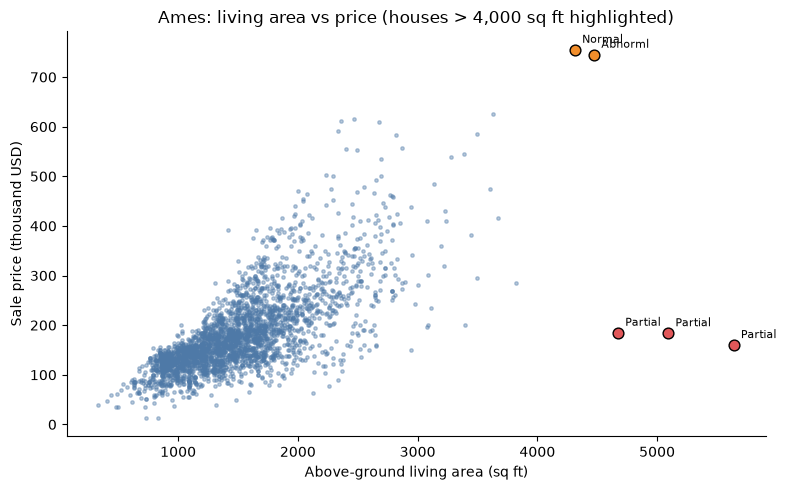

In [3]:
big = ames[ames["Gr_Liv_Area"] > 4000]
print(big[["Gr_Liv_Area", "Sale_Price", "Sale_Condition", "Neighborhood"]])

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(x, y / 1000, s=6, alpha=0.4, color="#4E79A7")
for _, r in big.iterrows():
    ax.scatter(r["Gr_Liv_Area"], r["Sale_Price"] / 1000, s=60, color="#E15759" if r["Sale_Condition"] == "Partial" else "#F28E2B",
               edgecolor="black", zorder=3)
    ax.annotate(r["Sale_Condition"], (r["Gr_Liv_Area"], r["Sale_Price"] / 1000), xytext=(5, 5), textcoords="offset points", fontsize=8)
ax.set(title="Ames: living area vs price (houses > 4,000 sq ft highlighted)", xlabel="Above-ground living area (sq ft)",
       ylabel="Sale price (thousand USD)")
plt.tight_layout()
plt.show()

Three very large houses sold far below the trend; all are **Partial** sales (the house was not finished at the time of sale). They are not typing errors, but they belong to a different process than normal sales. The dataset's documentation recommends removing houses above 4,000 sq ft for teaching models.

## 3. Multivariate Outliers: Isolation Forest

A point can be normal in every single column and unusual in the combination (a small house with a huge garage). **Isolation Forest** builds random trees; points that are isolated after few splits are unusual.

In [4]:
feat = ["Gr_Liv_Area", "Total_Bsmt_SF", "Garage_Area", "Lot_Area", "Year_Built", "Sale_Price"]
iso = IsolationForest(contamination=0.01, random_state=RNG).fit(ames[feat])
ames["iso_outlier"] = iso.predict(ames[feat]) == -1
ames["iso_score"] = -iso.score_samples(ames[feat])
top = ames.nlargest(6, "iso_score")[feat + ["Sale_Condition"]]
print(f"Isolation Forest flags {ames['iso_outlier'].sum()} houses (1 %); the most unusual:")
print(top.to_string())

Isolation Forest flags 30 houses (1 %); the most unusual:
      Gr_Liv_Area  Total_Bsmt_SF  Garage_Area  Lot_Area  Year_Built  Sale_Price Sale_Condition
1498       5642.0         6110.0       1418.0   63887.0      2008.0    160000.0        Partial
2180       5095.0         5095.0       1154.0   39290.0      2008.0    183850.0        Partial
1637       2338.0         2660.0       1110.0   51974.0      2006.0    591587.0        Partial
2666       3608.0         1107.0        840.0   22950.0      1892.0    475000.0         Normal
1767       4316.0         2444.0        832.0   21535.0      1994.0    755000.0         Normal
2445       3627.0         1930.0        807.0   35760.0      1995.0    625000.0         Normal


## 4. How Much Do Outliers Matter? Measure It

A linear regression of price on living area is sensitive to the three Partial sales: they pull the line down. The cell compares cross-validated errors **on normal houses** for four strategies.

In [5]:
X = ames[["Gr_Liv_Area"]].to_numpy()
normal = (ames["Gr_Liv_Area"] <= 4000).to_numpy()
cv = KFold(5, shuffle=True, random_state=RNG)

def cv_mae(model, X_fit, y_fit, keep=None):
    """5-fold CV; train on the given rows, evaluate on the normal houses of each test fold."""
    errs = []
    for tr, te in cv.split(X):
        tr = tr if keep is None else tr[keep[tr]]
        te = te[normal[te]]
        model.fit(X_fit[tr], y_fit[tr])
        errs.append(np.mean(np.abs(model.predict(X_fit[te]) - y.to_numpy()[te])))   # same transformation as in training
    return np.mean(errs)

lo, hi = np.percentile(X[:, 0], [1, 99])
X_wins = np.clip(X, lo, hi)
strategies = {
    "keep all (OLS)": cv_mae(LinearRegression(), X, y.to_numpy()),
    "remove > 4,000 sq ft (OLS)": cv_mae(LinearRegression(), X, y.to_numpy(), keep=normal),
    "winsorise area at 1st/99th pct (OLS)": cv_mae(LinearRegression(), X_wins, y.to_numpy()),
    "robust loss (Huber)": cv_mae(HuberRegressor(epsilon=1.35, max_iter=1000), X / 1000, y.to_numpy()),
}
print({k: f"${v:,.0f}" for k, v in strategies.items()})
coef_all = LinearRegression().fit(X, y).coef_[0]
coef_clean = LinearRegression().fit(X[normal], y[normal]).coef_[0]
print(f"\nprice per extra sq ft: {coef_all:.1f} USD with outliers, {coef_clean:.1f} USD without")

{'keep all (OLS)': '$38,102', 'remove > 4,000 sq ft (OLS)': '$38,315', 'winsorise area at 1st/99th pct (OLS)': '$38,568', 'robust loss (Huber)': '$37,905'}

price per extra sq ft: 111.7 USD with outliers, 116.2 USD without


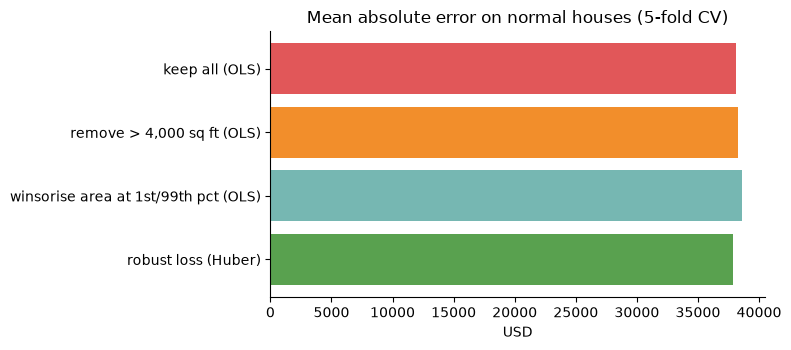

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(list(strategies)[::-1], list(strategies.values())[::-1], color=["#59A14F", "#76B7B2", "#F28E2B", "#E15759"])
ax.set(title="Mean absolute error on normal houses (5-fold CV)", xlabel="USD")
plt.tight_layout()
plt.show()

Each strategy predicts with the same transformation it was trained with (winsorised areas, or areas in thousands of square feet for the Huber optimiser). On this dataset the four strategies are within about 2 % of each other: five extreme houses among 2,930 barely move the predictions for normal houses. They do change the **coefficient** (the price of an extra square foot) by about 4 %. Outliers matter most for small datasets, for squared-error losses, and when you interpret coefficients; measure before you remove anything.

## 5. Decision Guide

| Situation | Action |
| :--- | :--- |
| clear error (impossible value) | fix or set to missing, then impute |
| different process (Partial sales, test transactions) | remove and **document**, or model separately |
| genuine but extreme values | keep; use log transforms, winsorising or robust losses |
| the outliers are the target (fraud, failures) | never remove: they are the signal (anomaly detection) |
| tree-based models | usually robust to outliers in features; still sensitive in the target for regression |

*Insight: Detect outliers with several rules and look at them before acting. Remove only what you can justify (errors, different processes), measure the effect on a validation set, and prefer transformations or robust losses for genuine extreme values.*

## Real-World Use Case or Analogy

Outliers are like **unusual results in a medical test**: a laboratory error is repeated or discarded, a rare but real value is treated with care, and some extreme values are exactly what the doctor is looking for. The response depends on the cause, not on the number alone.

Insurance and banking models cap extreme claims to stabilise estimates, while fraud teams build entire systems to find exactly the transactions that other models would treat as outliers.